In [83]:
import pandas as pd
import numpy as np

In [84]:
df = pd.read_csv(r"C:\Users\kunwa\PycharmProjects\Deep Learning\Churn_Modelling.csv")

In [85]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [86]:
df.drop(columns = ['RowNumber', 'CustomerId', 'Surname'], inplace=True)

C:\Users\kunwa\AppData\Local\Temp\ipykernel_26196\3466508716.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns = ['RowNumber', 'CustomerId', 'Surname'], inplace=True)


In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 859.5 KB


In [88]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

In [89]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,1,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,1,0,1


In [90]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop(columns=['Exited']), df['Exited'], test_size=0.2, random_state=42)

In [91]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [92]:
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense


In [93]:
model = Sequential()
model.add(Dense(11, activation='relu', input_dim=11))
model.add(Dense(11, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

C:\Users\kunwa\PycharmProjects\Deep Learning\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [94]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [95]:
model.compile(loss = 'binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [96]:
history = model.fit(x_train, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7922 - loss: 0.5061 - val_accuracy: 0.8056 - val_loss: 0.4417
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8036 - loss: 0.4434 - val_accuracy: 0.8219 - val_loss: 0.4182
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8172 - loss: 0.4260 - val_accuracy: 0.8263 - val_loss: 0.4039
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8255 - loss: 0.4114 - val_accuracy: 0.8381 - val_loss: 0.3901
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8355 - loss: 0.3971 - val_accuracy: 0.8450 - val_loss: 0.3787
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8420 - loss: 0.3849 - val_accuracy: 0.8494 - val_loss: 0.3700
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8486 - loss: 0.3748 - val_accuracy: 0.8506 - val_loss: 0.3619
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8527 - loss: 0.3673 - val_accu

In [97]:
model.layers[0].get_weights()


[array([[ 0.72841763, -0.37453544,  0.12448018, -0.33732817, -0.11430431,
          0.21261658, -0.0438443 , -0.10855145, -0.17154567,  0.02835843,
         -0.45355985],
        [-0.10598644,  0.43679997, -0.59457135, -0.11042672, -0.6392529 ,
         -0.11375102,  1.2015532 , -0.27391014,  0.18562406,  0.39285448,
         -0.14054874],
        [ 0.22349931,  0.11363174, -0.10536195, -0.0555661 ,  0.00931576,
         -0.3428346 , -0.06749327, -0.3350676 , -0.0631858 ,  0.2075811 ,
         -0.5874786 ],
        [-1.0530585 , -0.21652003,  0.49308467, -0.06914323, -0.33412006,
         -0.7483893 , -0.24692713,  0.14551365, -0.26783454,  0.33000192,
          0.18038751],
        [ 0.6232316 ,  0.03016798,  0.01021247, -0.1525916 , -0.05369872,
         -0.3033928 , -0.05208839, -0.23002972, -1.2268927 ,  0.8738427 ,
          0.6315335 ],
        [-0.13036868, -0.47786325, -0.2611583 ,  0.34717172, -0.25668886,
         -0.63360506,  0.01129863,  0.4475459 , -0.01835836, -0.3661758

In [98]:
model.layers[1].get_weights()

[array([[-0.10448135, -0.03054454, -0.257229  ,  0.3431073 ,  0.24314071,
         -0.08225564,  0.42768872,  0.3847071 ,  0.3892354 ,  0.06437032,
          0.5795432 ],
        [-0.46537822, -0.04039458, -0.01565698, -0.00416186,  0.45951054,
         -0.28288347,  0.24062055, -0.03690239,  0.05695352,  0.69148034,
          0.35933977],
        [-0.03535305, -0.82599354, -0.7136574 , -0.0376763 ,  0.29327685,
         -0.05116595,  0.07910741,  0.06809919,  0.29886666, -0.10096079,
         -0.52680403],
        [-0.64350986,  0.84307516, -0.11719878, -0.58725905, -0.05048323,
          0.4092831 ,  0.31306168,  0.09744953,  0.29010424, -0.05587276,
         -0.0443258 ],
        [-0.84308594,  0.09609609,  0.4144375 , -0.28999913, -0.7597157 ,
         -0.09062076, -0.45196596,  0.57861894,  0.07149547,  0.16667257,
         -0.4049922 ],
        [ 0.30103475, -2.161564  ,  0.16654594, -0.03610831,  0.38700736,
          0.29496115, -0.04936156,  0.31152412,  0.29781514,  0.0256927

In [99]:
y_pred = model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [100]:
y_pred = np.where(y_pred > 0.5, 1, 0)

In [101]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.86

In [102]:
import matplotlib.pyplot as plt


In [103]:
history.history

{'accuracy': [0.792187511920929,
  0.8035937547683716,
  0.817187488079071,
  0.8254687786102295,
  0.8354687690734863,
  0.8420312404632568,
  0.8485937714576721,
  0.8526562452316284,
  0.8535937666893005,
  0.8542187213897705,
  0.8573437333106995,
  0.8582812547683716,
  0.8582812547683716,
  0.859375,
  0.8598437309265137,
  0.8596875071525574,
  0.8598437309265137,
  0.8609374761581421,
  0.8607812523841858,
  0.8617187738418579,
  0.8631250262260437,
  0.8614062666893005,
  0.8623437285423279,
  0.8623437285423279,
  0.8628125190734863,
  0.8637499809265137,
  0.86328125,
  0.8637499809265137,
  0.8646875023841858,
  0.8645312786102295,
  0.8642187714576721,
  0.8648437261581421,
  0.8653125166893005,
  0.8635937571525574,
  0.8646875023841858,
  0.8653125166893005,
  0.8628125190734863,
  0.8654687404632568,
  0.8654687404632568,
  0.8667187690734863,
  0.8656250238418579,
  0.8660937547683716,
  0.8662499785423279,
  0.8662499785423279,
  0.8690624833106995,
  0.86609375476837

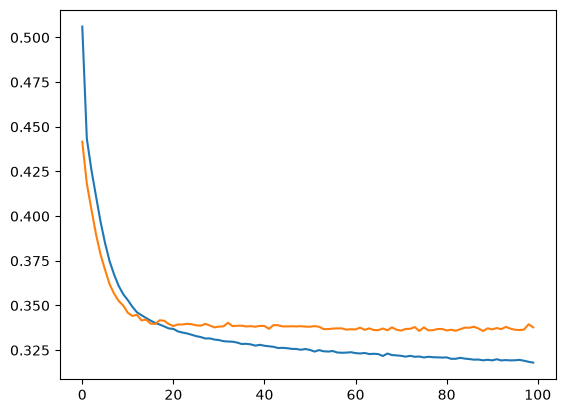

In [104]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

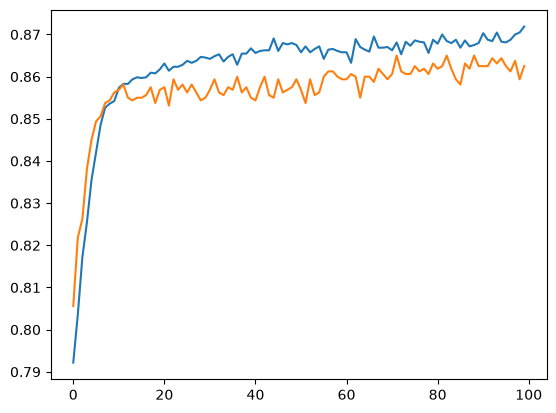

In [105]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])